# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

  Obtaining dependency information for pandas from https://files.pythonhosted.org/packages/d3/dc/d2df02854aec5d47659acfb2be352eecc691845b2f86e99c84f1010a8671/pandas-3.0.6-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for seaborn from https://files.pythonhosted.org/packages/83/11/00d3c3dfc25ad54e731d91449895a79e4bf2384dc3ac01809010ba88f6d5/seaborn-0.13.2-py3-none-any.whl.metadata
  Obtaining dependency information for scikit-learn from https://files.pythonhosted.org/packages/29/8a/8d1e888fe3d0dd4e2a1f3356dad703eed569aaf673e222b6f647005ad30f/scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for tzdata from https://files.pythonhosted.org/packages/94/21/1e5995a1c920cce14e4bffae20c665ec10e7ed03ab25e006cd741092b718/tzdata-2026.5-py2.py3-none-any.whl.metadata
  Obtaining dependency information for scipy>=1.10.0 from https://files.pythonhosted.org/packages/95/da/0d1df507cf574b3f224ccc3d45244c9a1d732c81dcb26b1e8a766ae271a8/scipy-1.1


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [6]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)
df.head()


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [9]:
print("Forma:", df.shape)
print("\nTipos:\n", df.dtypes.value_counts())
print("\nNulos totales:", int(df.isna().sum().sum()))
print("Duplicados:", int(df.duplicated().sum()))
print("\nDistribución de target:")
print(df["target"].value_counts().sort_index())
print((df["target"].value_counts(normalize=True).sort_index() * 100).round(1))

Forma: (178, 14)

Tipos:
 float64    13
int64       1
Name: count, dtype: int64

Nulos totales: 0
Duplicados: 0

Distribución de target:
target
0    59
1    71
2    48
Name: count, dtype: int64
target
0    33.1
1    39.9
2    27.0
Name: proportion, dtype: float64


**Conclusión de calidad:**

> Describe brevemente qué encontraste y qué decisión tomaste.

## 2. Split train/test

In [10]:
train_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df["target"], random_state=RANDOM_STATE
)

In [11]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

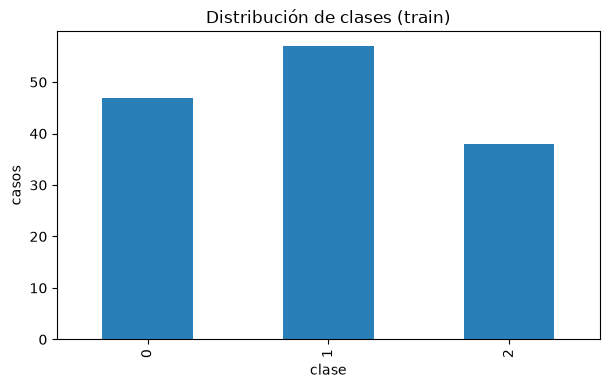

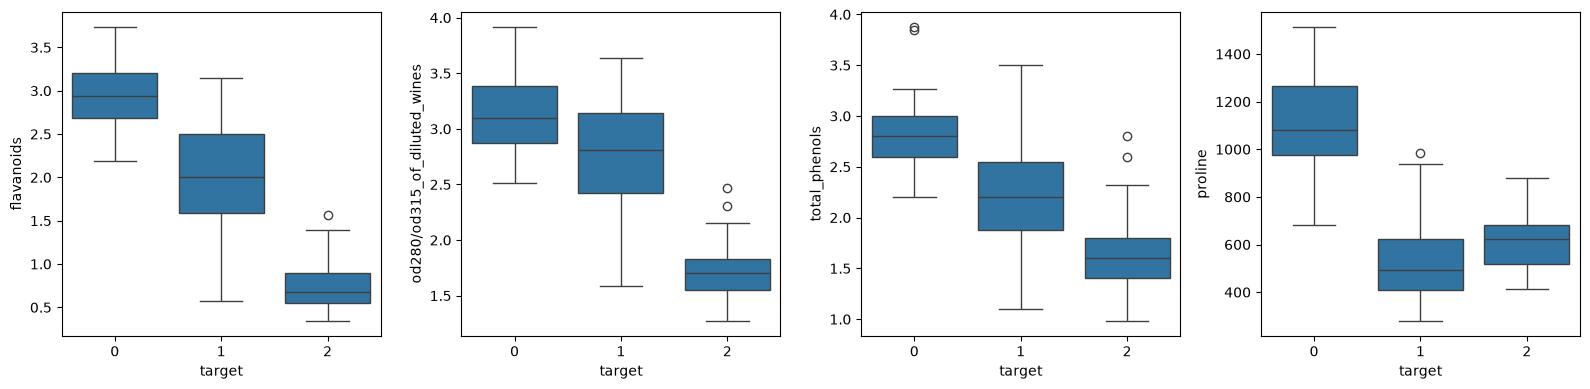

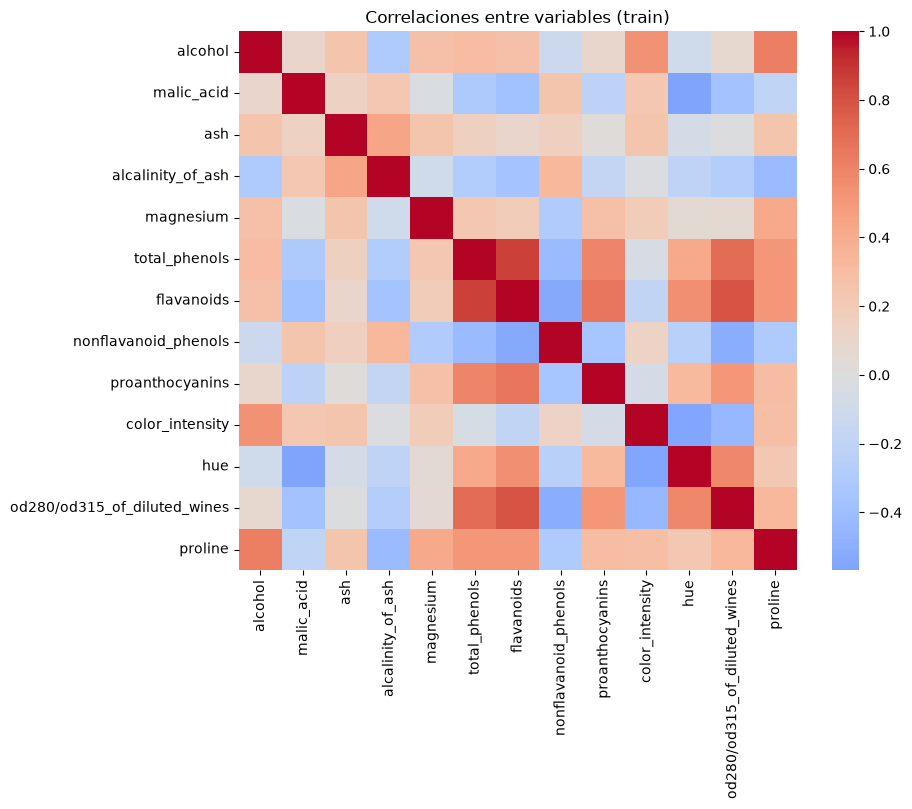

In [12]:
feature_names = [c for c in train_df.columns if c != "target"]

# 1) Distribución de clases
train_df["target"].value_counts().sort_index().plot.bar(color="#2980b9")
plt.title("Distribución de clases (train)"); plt.xlabel("clase"); plt.ylabel("casos")
plt.show()

# 2) Boxplots de las 4 variables más relacionadas con la clase
corr = train_df.corr(numeric_only=True)["target"].drop("target").abs().sort_values(ascending=False)
top4 = corr.head(4).index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, top4):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
plt.tight_layout(); plt.show()

# 3) Correlaciones
plt.figure(figsize=(9, 7))
sns.heatmap(train_df[feature_names].corr(), cmap="coolwarm", center=0)
plt.title("Correlaciones entre variables (train)")
plt.show()

**Hallazgos:**

1. **Desbalance moderado de clases.** En train hay ~47 casos de la clase 0, ~57 de la clase 1 y ~38 de la clase 2. No es un desbalance severo, pero justifica el split estratificado y la validación cruzada estratificada, y obliga a revisar F1 macro además de accuracy.
2. **Ninguna variable separa las tres clases por sí sola.** `flavanoids`, `total_phenols` y `od280/od315` bajan de la clase 0 a la 2 y separan bien los extremos, pero la clase 1 se solapa con ambos. `proline` separa la clase 0 (~1100) de las clases 1 y 2 (~500–650), pero esas dos se solapan entre sí. Hace falta combinar variables, así que un modelo multivariado es mejor que una regla con un solo umbral.
3. **Escalas muy distintas y variables muy correlacionadas.** `proline` está en cientos o miles y `flavanoids` entre 0.5 y 3.5, por lo que regresión logística y KNN requieren estandarización dentro del pipeline. Además `flavanoids`, `total_phenols` y `od280/od315` están fuertemente correlacionadas (~0.8 o más). Esto no perjudica a árboles ni a KNN, pero hay que ser cuidadoso al interpretar coeficientes o importancias.

## 4. Persistencia de datos y contrato

In [13]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "dataset": "Wine",
    "target": "target",
    "target_names": [f"class_{c}" for c in sorted(df["target"].unique())],
    "features": feature_names,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(json.dumps(contract, indent=2), encoding="utf-8")

437

In [14]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.